# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

The input files are in `data/` at the project root. In Colab, the next cell asks you to upload them
if they are unavailable.

In [100]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "Baraniuk"

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [ ]:
NEEDED = ["train.csv", "weather_forecast.csv"]
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"

if not all((DATA_DIR / name).exists() for name in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
        DATA_DIR = Path.cwd()
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} in {DATA_DIR}.")

data = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv(DATA_DIR / "weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

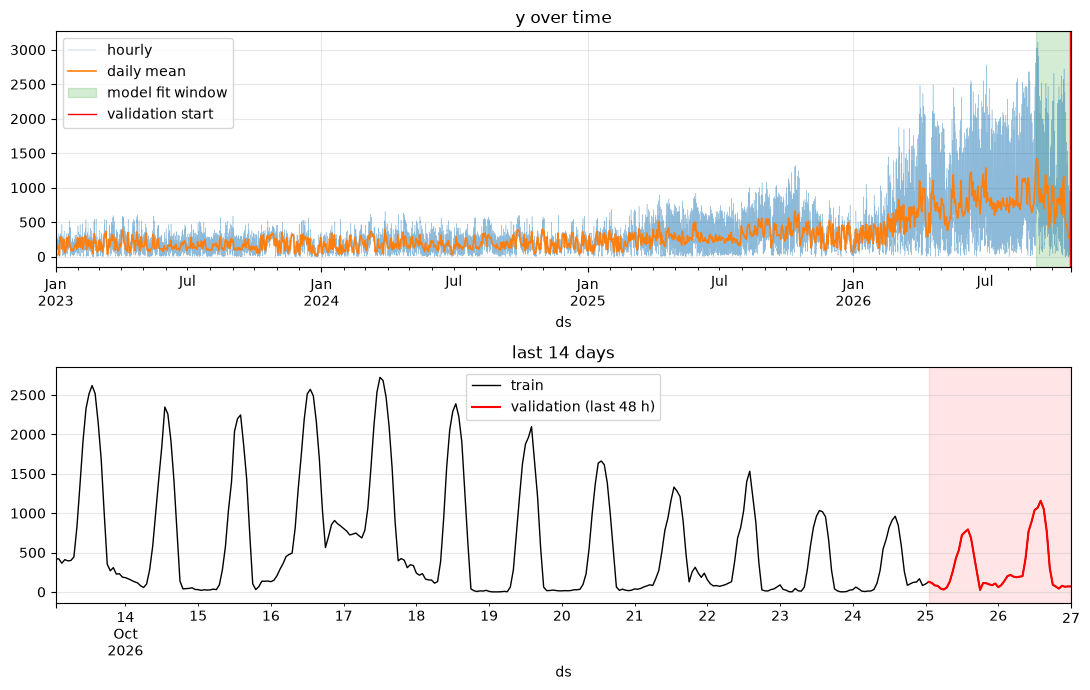

In [102]:
s = data.set_index("ds")["y"]
split = data["ds"].iloc[-H]                 # first validation hour
train_start = data["ds"].iloc[-M * H]       # start of the window the models are fit on

fig, ax = plt.subplots(2, 1, figsize=(11, 7))

s.plot(ax=ax[0], lw=0.3, alpha=0.5, label="hourly")
s.resample("D").mean().plot(ax=ax[0], lw=1.2, label="daily mean")
ax[0].axvspan(train_start, split, color="tab:green", alpha=0.2, label="model fit window")
ax[0].axvline(split, color="red", lw=1, label="validation start")
ax[0].set_title("y over time"); ax[0].legend()

z = s[s.index > s.index[-1] - pd.Timedelta(days=14)]                         # zoom: last 2 weeks
z.plot(ax=ax[1], color="black", lw=1, label="train")
z[split:].plot(ax=ax[1], color="red", lw=1.5, label="validation (last 48 h)")
ax[1].axvspan(split, z.index[-1], color="red", alpha=0.1)
ax[1].set_title("last 14 days"); ax[1].legend()

plt.tight_layout(); plt.show()

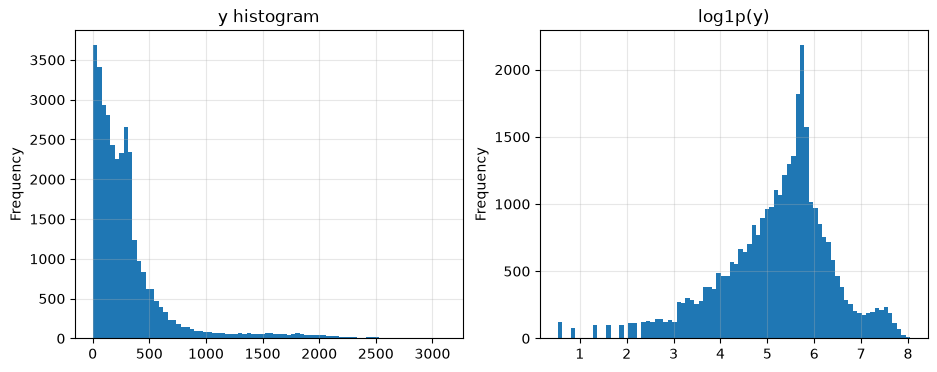

In [103]:
fig, ax = plt.subplots(1, 2)
s.plot.hist(bins=80, ax=ax[0], title="y histogram")
np.log1p(s).plot.hist(bins=80, ax=ax[1], title="log1p(y)")
plt.show()

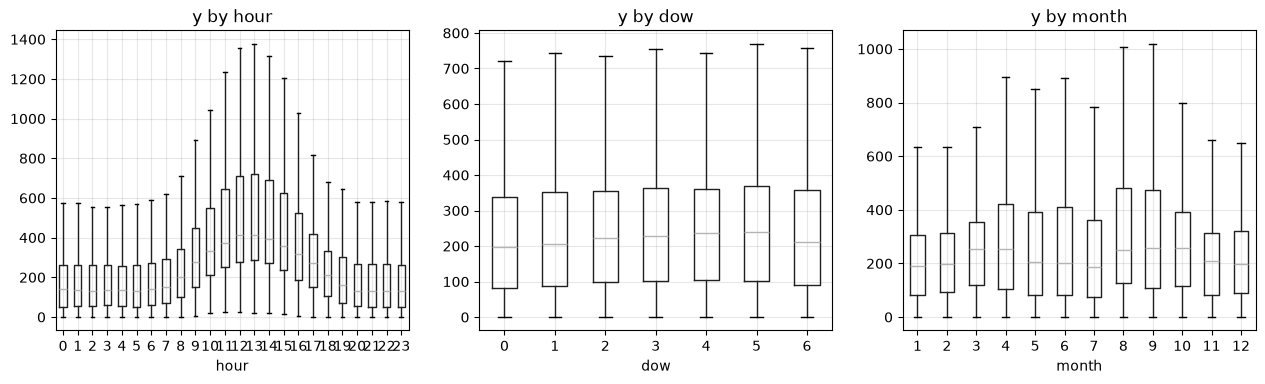

In [104]:
d = data.assign(hour=data.ds.dt.hour, dow=data.ds.dt.dayofweek, month=data.ds.dt.month)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["hour", "dow", "month"]):
    d.boxplot(column="y", by=col, ax=a, showfliers=False)
    a.set_title(f"y by {col}"); a.set_xlabel(col)
plt.suptitle(""); plt.show()


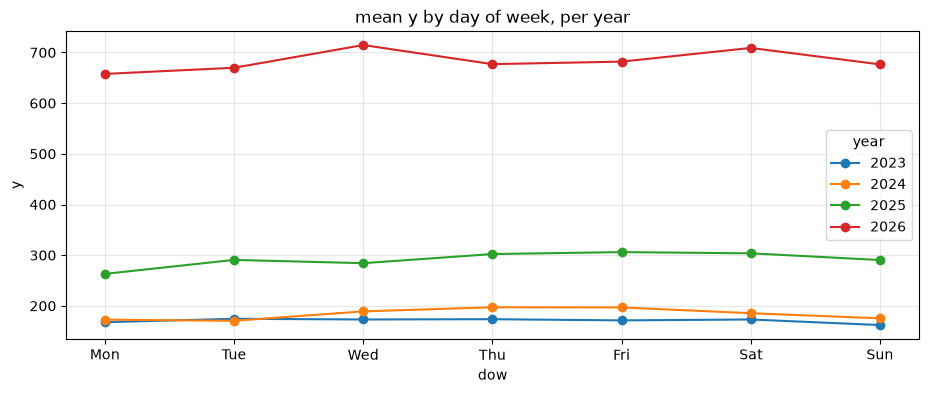

In [105]:
d = data.assign(dow=data.ds.dt.day_of_week, year=data.ds.dt.year)

ax = d.pivot_table(index="dow", columns="year", values="y", aggfunc="mean").plot(marker="o")
ax.set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_title("mean y by day of week, per year"); ax.set_ylabel("y")
plt.show()

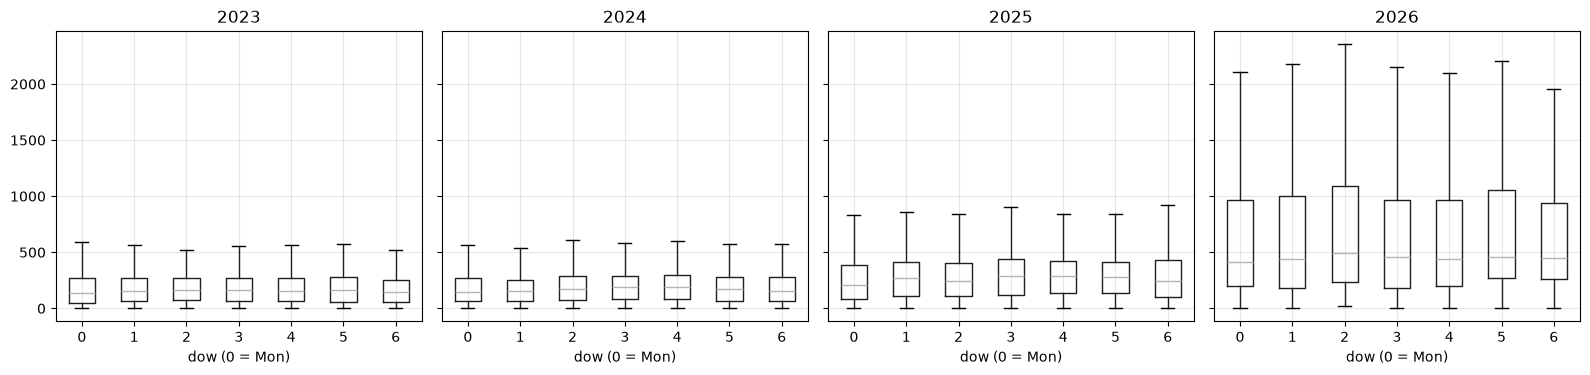

In [106]:
years = sorted(d.year.unique())
fig, ax = plt.subplots(1, len(years), figsize=(4 * len(years), 4), sharey=True)
for a, yr in zip(ax, years):
    d[d.year == yr].boxplot(column="y", by="dow", ax=a, showfliers=False)
    a.set_title(str(yr)); a.set_xlabel("dow (0 = Mon)")
plt.suptitle(""); plt.tight_layout(); plt.show()

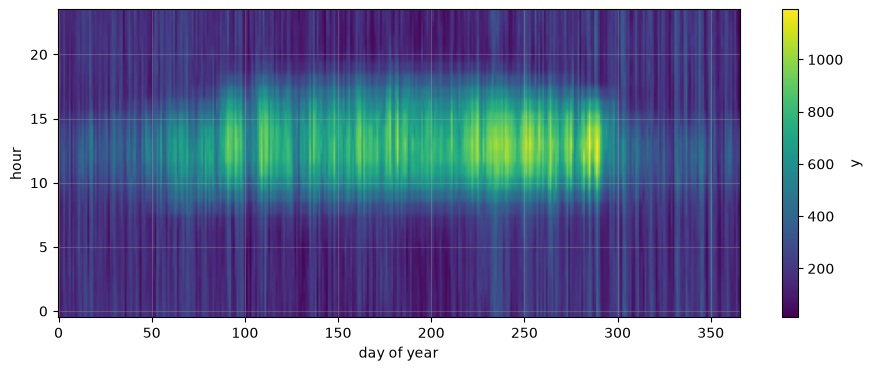

In [107]:
pv = d.pivot_table(index=d.ds.dt.hour, columns=d.ds.dt.dayofyear, values="y", aggfunc="mean")
plt.imshow(pv, aspect="auto", cmap="viridis", origin="lower")
plt.colorbar(label="y"); plt.xlabel("day of year"); plt.ylabel("hour")
plt.show()

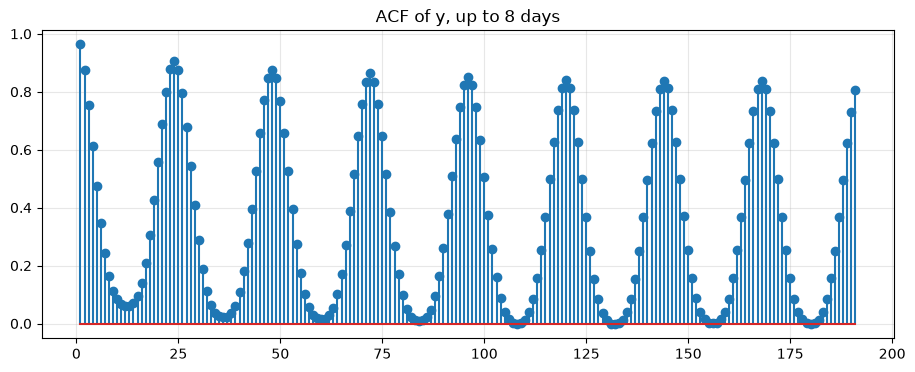

In [108]:
from pandas.plotting import autocorrelation_plot
lags = range(1, 24 * 8)
plt.stem(lags, [s.autocorr(l) for l in lags]); plt.title("ACF of y, up to 8 days"); plt.show()

### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [109]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [110]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

In [111]:
from statsforecast.models import AutoETS
from statsforecast.utils import ConformalIntervals

for t in (data, weather_fc):
    t["sun"] = t.daylight * (1 - t.cloud_cover)   # clear-sky daylight
EX = ["sun", "wind_speed", "cloud_cover", "daylight", "temperature", "humidity"]

df = data[["ds", "y"] + EX].tail(M * H).copy()
df["y"] = np.log(df.y)                          # multiplicative -> additive
df["unique_id"] = "y"
X_future = weather_fc[["ds"] + EX].assign(unique_id="y")

CI = ConformalIntervals(h=H, n_windows=5)       # 95% from real 48h-ahead errors on 5 past windows


def run(model, df, X_valid=None, X_future=None, ci=CI):
    sf = StatsForecast(models=[model], freq="h")
    c = [model.alias, f"{model.alias}-lo-95", f"{model.alias}-hi-95"]
    v = sf.forecast(df=df.iloc[:-H], h=H, level=[95], X_df=X_valid, prediction_intervals=ci)
    f = sf.forecast(df=df, h=H, level=[95], X_df=X_future, prediction_intervals=ci)
    return [np.exp(v[x].values) for x in c], [np.exp(f[x].values) for x in c]

In [112]:
df.head()

,ds,y,sun,wind_speed,cloud_cover,daylight,temperature,humidity,unique_id
32328,2026-09-09 01:00:00,6.465,0.0,1,1.0,0,17,55,y
32329,2026-09-09 02:00:00,6.461,0.0,1,1.0,0,17,55,y
32330,2026-09-09 03:00:00,6.442,0.0,1,1.0,0,15,59,y
32331,2026-09-09 04:00:00,6.480,0.0,4,1.0,0,13,72,y
32332,2026-09-09 05:00:00,6.557,0.0,4,1.0,0,13,72,y


In [113]:
ets_v, ets_f = run(AutoETS(season_length=M, model="AAA"), df[["unique_id", "ds", "y"]])

In [114]:
results.loc["ETS conformal"] = score(valid, *ets_v)
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.000
ETS conformal,121.870,41.444,1245.617,0.938


In [115]:
ets_v, ets_f = run(AutoETS(season_length=M, model="AAA"), df[["unique_id", "ds", "y"]])
# arima_v, arima_f = run(AutoARIMA(season_length=M), df,
#                        X_valid=df.iloc[-H:].drop(columns="y"), X_future=X_future)

results.loc["ETS conformal"] = score(valid, *ets_v)
# results.loc["ARIMA+weather conformal"] = score(valid, *arima_v)
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.000
ETS conformal,121.870,41.444,1245.617,0.938


In [116]:
from statsforecast.models import MSTL

# MSTL on the same 48-day window as ARIMA/ETS: daily (24) + weekly (168) seasonality on log(y),
# weather goes into the ARIMA on trend + remainder. Yearly season would need >= 2 years and runs too long.
mstl = MSTL(season_length=[M, 7 * M], trend_forecaster=AutoARIMA(season_length=1))
mstl_v, mstl_f = run(mstl, df, X_valid=df.iloc[-H:].drop(columns="y"), X_future=X_future,
                     ci=ConformalIntervals(h=H, n_windows=3))

results.loc["MSTL(24, 168)+weather conformal"] = score(valid, *mstl_v)
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.000
ETS conformal,121.870,41.444,1245.617,0.938
"MSTL(24, 168)+weather conformal",171.596,50.307,2185.235,0.667


In [117]:
# ETS with 20 conformal windows: 20 errors per horizon hour give a far steadier 95% quantile than 5
ets20_v, ets20_f = run(AutoETS(season_length=M, model="AAA"), df[["unique_id", "ds", "y"]],
                       ci=ConformalIntervals(h=H, n_windows=20))
results.loc["ETS conformal 20"] = score(valid, *ets20_v)
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.000
ETS conformal,121.870,41.444,1245.617,0.938
"MSTL(24, 168)+weather conformal",171.596,50.307,2185.235,0.667
ETS conformal 20,121.870,41.444,887.158,0.938


In [118]:
def combo(ets, bench):
    # average the two point forecasts, keep the benchmark's interval (widened if the point falls outside)
    point = (ets[0] + bench[0]) / 2
    return [point, np.minimum(bench[1], point), np.maximum(bench[2], point)]


results.loc["combo ETS+snaive"] = score(valid, *combo(ets20_v, bench))
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.000
ETS conformal,121.870,41.444,1245.617,0.938
"MSTL(24, 168)+weather conformal",171.596,50.307,2185.235,0.667
ETS conformal 20,121.870,41.444,887.158,0.938
combo ETS+snaive,114.196,39.090,568.464,1.000


In [119]:
from scipy.stats import norm


def interval_metrics(a, p, lo, hi, alpha=0.05):
    a, p, lo, hi = (np.asarray(x, float) for x in (a, p, lo, hi))
    cov = np.mean((a >= lo) & (a <= hi))
    pin = lambda q, t: np.mean(np.maximum(t * (a - q), (t - 1) * (a - q)))
    sigma = np.maximum((hi - lo) / (2 * norm.ppf(1 - alpha / 2)), 1e-9)   # normal fitted to the interval
    z = (a - p) / sigma
    crps = np.mean(sigma * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi)))
    return {"Winkler": winkler(a, lo, hi, alpha), "CRPS": crps,
            "pinball": (pin(lo, alpha / 2) + pin(hi, 1 - alpha / 2)) / 2,
            "width": np.mean(hi - lo), "coverage": cov, "ACE": cov - (1 - alpha)}


def scale(fc, c):
    # shrink (c < 1) or widen (c > 1) the interval around the point forecast
    p, lo, hi = fc
    return [p, np.clip(p - c * (p - lo), 0, None), p + c * (hi - p)]


rows = {"snaive": bench, "ETS conformal 20": ets20_v, "combo": combo(ets20_v, bench)}
rows |= {f"combo x{k}": scale(combo(ets20_v, bench), k) for k in (0.5, 0.6, 0.7, 0.8, 0.9)}
pd.DataFrame({n: interval_metrics(valid, *r) for n, r in rows.items()}).T

,Winkler,CRPS,pinball,width,coverage,ACE
snaive,568.464,66.273,7.106,568.464,1.000,0.050
ETS conformal 20,887.158,74.456,11.089,740.446,0.938,-0.012
combo,568.464,63.945,7.106,568.464,1.000,0.050
combo x0.5,348.815,65.651,4.360,284.232,0.896,-0.054
combo x0.6,344.291,64.022,4.304,341.078,0.979,0.029
combo x0.7,397.925,63.148,4.974,397.925,1.000,0.050
combo x0.8,454.771,62.914,5.685,454.771,1.000,0.050
combo x0.9,511.617,63.210,6.395,511.617,1.000,0.050


In [ ]:
# Sliding-window CV: the train window keeps the same length (DAYS) and moves forward with the origin,
# exactly like the final model, which is fit on the last DAYS days only.
DAYS = 46
origins = [len(y) - k * H for k in (1, 2, 3)]                       # last 3 non-overlapping 48 h windows
origins += [int(data.index[data.ds == f"{yr}-10-27 00:00:00"][0]) + 1 for yr in (2023, 2024, 2025)]  # same dates, past years


def ets_fc(o):
    df = data[["ds", "y"]].iloc[o - DAYS * M:o].copy()
    df["y"] = np.log(df.y)
    df["unique_id"] = "y"
    fc = StatsForecast(models=[AutoETS(season_length=M, model="AAA")], freq="h").forecast(df=df, h=H)
    return np.exp(fc["AutoETS"].values)


def candidates(o):
    past = y[:o]
    sn = snaive(past)
    dm = np.tile(past[-3 * M:].reshape(3, M).mean(0), H // M)
    e = ets_fc(o)
    sn_interval = lambda p, c=1.0: scale([p, np.minimum(sn[1], p), np.maximum(sn[2], p)], c)
    p3 = (e + sn[0] + dm) / 3
    return {"snaive": sn,
            "combo ETS+snaive x0.7": sn_interval((e + sn[0]) / 2, 0.7),
            "ETS+snaive+day3 x1.0": sn_interval(p3),
            "ETS+snaive+day3 x0.7 (chosen)": sn_interval(p3, 0.7)}


rows = []
for o in origins:
    a = y[o:o + H]
    for name, (p, lo, hi) in candidates(o).items():
        for part, sl in [("h1-24", slice(0, 24)), ("h25-48", slice(24, 48)), ("all", slice(0, 48))]:
            rows.append({"origin": str(data.ds[o]), "model": name, "part": part,
                         **score(a[sl], p[sl], lo[sl], hi[sl])})
cv = pd.DataFrame(rows)

skill = cv[cv.part == "all"].pivot(index="origin", columns="model", values="RMSE")
skill = skill.div(skill["snaive"], axis=0)                          # < 1 means the model beats the benchmark
print("RMSE skill per origin:"); display(skill.round(2))
cv.pivot_table(index="model", columns="part", values=["RMSE", "MAPE", "Winkler", "coverage"], aggfunc="mean").round(2)

In [120]:
C = 0.7                 # interval scale; 0.6 already misses one hour on validation, 0.7 keeps a margin
sn = snaive(y)
dm = np.tile(y[-3 * M:].reshape(3, M).mean(0), H // M)   # mean of the last 3 days at the same hour
p = (ets20_f[0] + sn[0] + dm) / 3                        # ETS + snaive + 3-day mean: skill 0.85 over 14 rolling origins
best = scale([p, np.minimum(sn[1], p), np.maximum(sn[2], p)], C)

## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

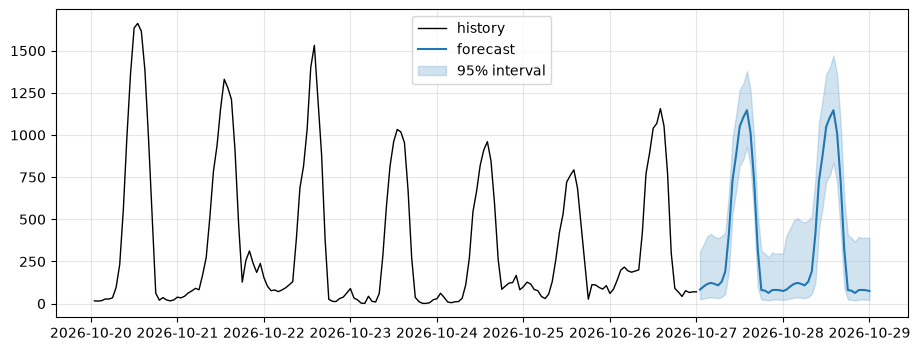

In [121]:
forecast, lower_95, upper_95 = best
lower_95 = np.clip(lower_95, 0, None)

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

In [ ]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(exist_ok=True)
FILE = OUTPUT_DIR / f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(str(FILE))
except ImportError:
    pass

Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.